In [18]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from torch import nn


In [19]:
with open("mnist_small.pickle", "rb") as file:
    data = pickle.load(file)

In [20]:
_X = data["_X"].astype(np.float64)
_Y = data["_Y"].astype(np.int32)
print(_X.shape)
print(_X.dtype)
print(_Y.shape)
print(_Y.dtype)

(8000, 1, 28, 28)
float64
(8000, 1)
int32


In [21]:
# Split data into train and test sets
_X_train, _X_test, _Y_train, _Y_test = train_test_split(
    _X, _Y, test_size=0.2, random_state=42
)
print(_X_train.shape)
print(_Y_train.shape)
print(_X_test.shape)
print(_Y_test.shape)

(6400, 1, 28, 28)
(6400, 1)
(1600, 1, 28, 28)
(1600, 1)


In [22]:
def scaler_transform(X):
    _mean = np.mean(X)
    _std = np.std(X)
    return (X - _mean) / _std


In [23]:
# Scale the data
# Note that we don't use SKLearn's StandardScaler here because our data is 4D and SKLearn's StandardScaler only works with 2D data.
# Therefore, we have to do it manually. We need to calculate mean and std of the training data.
_mean = np.mean(_X_train)
_std = np.std(_X_train)
print(f"Mean: {_mean}, Std: {_std}")

Mean: 33.1859935028699, Std: 78.40978966456821


In [24]:
# Scale the X data
X_train = (_X_train - _mean) / _std
X_test = (_X_test - _mean) / _std

# Check the range of X before and after scaling
print("_X_train (before scaling):", _X_train.min(), "to", _X_train.max())
print("X_train (after scaling):", X_train.min(), "to", X_train.max())

# No scaling for labels
Y_train = _Y_train
Y_test = _Y_test


_X_train (before scaling): 0.0 to 255.0
X_train (after scaling): -0.4232378845146421 to 2.828907046505742


In [25]:
# Convert to PyTorch tensors
X_train_pt = torch.tensor(X_train, dtype=torch.float32)
X_test_pt = torch.tensor(X_test, dtype=torch.float32)

# For labels, we need to convert them to long type because CrossEntropyLoss expects the target labels to be of type long.
Y_train_pt = torch.tensor(Y_train, dtype=torch.long)
Y_test_pt = torch.tensor(Y_test, dtype=torch.long)

In [26]:
# Shape of one image as it flows through the model:
#   (1, 28, 28) --Conv2d--> (16, 28, 28) --MaxPool2d--> (16, 14, 14)
#               --Conv2d--> (32, 14, 14) --MaxPool2d--> (32, 7, 7)
#               --AdaptiveAvgPool2d--> (32, 4, 4) --Flatten--> (512,)
#               --Linear--> (10,)  one logit per class
num_classes = 10
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),  # 1 input channel -> 16 filters
    nn.ReLU(),
    nn.MaxPool2d(2),  # 28x28 -> 14x14
    nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 16 channels -> 32 filters
    nn.ReLU(),
    nn.MaxPool2d(2),  # 14x14 -> 7x7
    nn.AdaptiveAvgPool2d((4, 4)),  # 7x7 -> 4x4 (fixed output size)
    nn.Flatten(),  # (32, 4, 4) -> 512 numbers
    nn.Linear(32 * 4 * 4, num_classes),  # 512 features -> 10 logits
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

In [27]:
# (Optional) LeNet-5 -- uncomment this cell to use it instead of the model above.
# The classic CNN by LeCun et al. (1998), adapted for 28x28 MNIST images.
# Shape of one image as it flows through the model:
#   (1, 28, 28) --Conv2d(5x5, pad 2)--> (6, 28, 28) --AvgPool2d--> (6, 14, 14)
#               --Conv2d(5x5)-------> (16, 10, 10) --AvgPool2d--> (16, 5, 5)
#               --Flatten--> (400,) --Linear--> (120,) --Linear--> (84,) --Linear--> (10,)

model = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2),  # 1 input channel -> 6 filters
    nn.Tanh(),
    nn.AvgPool2d(2),  # 28x28 -> 14x14
    nn.Conv2d(6, 16, kernel_size=5),  # no padding: 14x14 -> 10x10
    nn.Tanh(),
    nn.AvgPool2d(2),  # 10x10 -> 5x5
    nn.Flatten(),  # (16, 5, 5) -> 400 numbers
    nn.Linear(16 * 5 * 5, 120),
    nn.Tanh(),
    nn.Linear(120, 84),
    nn.Tanh(),
    nn.Linear(84, num_classes),  # 84 features -> 10 logits
)

# Re-create the optimizer so it updates the NEW model's parameters
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [28]:
# Function to get batches of indices
def get_batches_indices(num_samples, batch_size):
    indices = np.arange(num_samples)
    np.random.shuffle(indices)
    for start_idx in range(0, num_samples, batch_size):
        end_idx = min(start_idx + batch_size, num_samples)
        batch_indices = indices[start_idx:end_idx]
        yield batch_indices


# Example usage
num_samples = 20
batch_size = 6
for idxes in get_batches_indices(num_samples, batch_size):
    print(idxes)


[ 9  4  5 12  2 14]
[13  6  0  8  3 16]
[10 18 17  1 11  7]
[15 19]


In [29]:
def calc_metrices(logits: torch.Tensor, labels: torch.Tensor, isPrint=False):
    # Apply softmax to logits to obtain prediction probabilities for each class
    probs = F.softmax(logits, dim=1)  # Shape: (batch_size, num_classes)

    # Use argmax to get the predicted class index for each sample
    preds = torch.argmax(probs, dim=1)  # Shape: (batch_size)

    # Move prediction and label tensors to CPU and convert to numpy arrays for scikit-learn compatibility
    preds_np = preds.cpu().numpy()
    labels_np = labels.cpu().numpy()

    # Generate the classification report as a dictionary (includes precision, recall, f1, etc.)
    report = classification_report(labels_np, preds_np, output_dict=True)

    # Optionally print a nicely formatted classification report if isPrint is True
    if isPrint:
        print(classification_report(labels_np, preds_np, digits=3))

    # Return the report dictionary and the numpy arrays of predictions and labels
    return report, preds_np, labels_np

In [30]:
loss_arr = []
F1_arr = []

In [31]:
n_epochs = 20  # number of epochs to run
batch_size = 10  # size of each batch

for epoch in range(n_epochs):
    # Training Phase
    model.train()
    epoch_train_loss = 0.0
    epoch_train_f1 = 0.0
    logit_arr = []
    label_arr = []

    for idxes in get_batches_indices(len(X_train_pt), batch_size):
        X_batch_pt = X_train_pt[idxes]
        Y_batch_pt = Y_train_pt[idxes]
        optimizer.zero_grad()
        Y_pred = model(X_batch_pt)
        loss = loss_fn(
            Y_pred, Y_batch_pt.view(-1)
        )  # view(-1) is used to flatten the labels to the shape (batch_size, ) which is required by CrossEntropyLoss
        # Backward pass
        loss.backward()

        # Optional gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Gradient clipping

        # Update weights
        optimizer.step()
        # Multiplies the average loss per sample by the number of
        # samples in the batch to get the total loss for this batch.
        epoch_train_loss += loss.item() * len(idxes)
        logit_arr.append(Y_pred)
        label_arr.append(Y_batch_pt)

    avg_train_loss = epoch_train_loss / len(X_train)
    loss_arr.append(avg_train_loss)

    logits = torch.concat(logit_arr, dim=0)
    labels = torch.concat(label_arr, dim=0)
    metrices, _, _ = calc_metrices(logits=logits, labels=labels.view(-1))
    avg_train_f1 = metrices["weighted avg"]["f1-score"]
    F1_arr.append(avg_train_f1)

    print(
        f"Epoch {epoch + 1}/{n_epochs}, Training Loss: {avg_train_loss:.4f}, Training F1-Score: {avg_train_f1:.4f}"
    )

Epoch 1/20, Training Loss: 0.5056, Training F1-Score: 0.8466
Epoch 2/20, Training Loss: 0.2060, Training F1-Score: 0.9369
Epoch 3/20, Training Loss: 0.1325, Training F1-Score: 0.9591
Epoch 4/20, Training Loss: 0.0935, Training F1-Score: 0.9706
Epoch 5/20, Training Loss: 0.0691, Training F1-Score: 0.9772
Epoch 6/20, Training Loss: 0.0452, Training F1-Score: 0.9852
Epoch 7/20, Training Loss: 0.0312, Training F1-Score: 0.9909
Epoch 8/20, Training Loss: 0.0276, Training F1-Score: 0.9914
Epoch 9/20, Training Loss: 0.0196, Training F1-Score: 0.9953
Epoch 10/20, Training Loss: 0.0141, Training F1-Score: 0.9956
Epoch 11/20, Training Loss: 0.0152, Training F1-Score: 0.9933
Epoch 12/20, Training Loss: 0.0119, Training F1-Score: 0.9967
Epoch 13/20, Training Loss: 0.0132, Training F1-Score: 0.9952
Epoch 14/20, Training Loss: 0.0121, Training F1-Score: 0.9961
Epoch 15/20, Training Loss: 0.0085, Training F1-Score: 0.9978
Epoch 16/20, Training Loss: 0.0073, Training F1-Score: 0.9972
Epoch 17/20, Trai

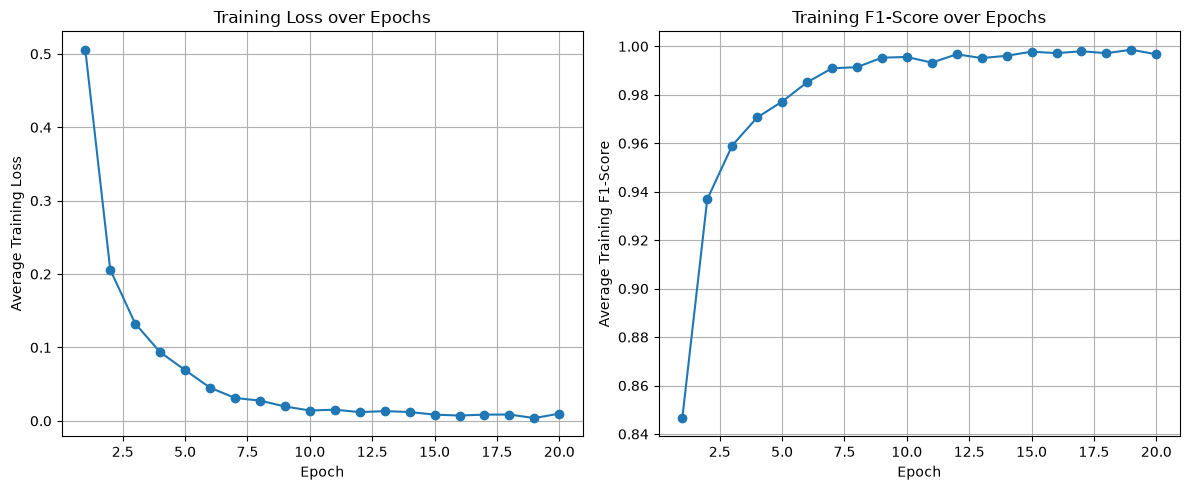

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(range(1, len(loss_arr) + 1), loss_arr, marker="o")
axes[0].set_title("Training Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Average Training Loss")
axes[0].grid()

axes[1].plot(range(1, len(F1_arr) + 1), F1_arr, marker="o")
axes[1].set_title("Training F1-Score over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Average Training F1-Score")
axes[1].grid()

plt.tight_layout()
plt.show()

In [33]:
# Evaluation Phase
model.eval()
with torch.no_grad():
    Y_pred_test = model(X_test_pt)
    test_loss = loss_fn(Y_pred_test, Y_test_pt.view(-1)).item()
    report, preds_np, labels_np = calc_metrices(
        logits=Y_pred_test, labels=Y_test_pt.view(-1), isPrint=False
    )

print(f"Test Loss: {test_loss:.4f}")
print(f"Test F1-Score: {report['weighted avg']['f1-score']:.4f}")

Test Loss: 0.1825
Test F1-Score: 0.9637


Number of misclassified samples: 58


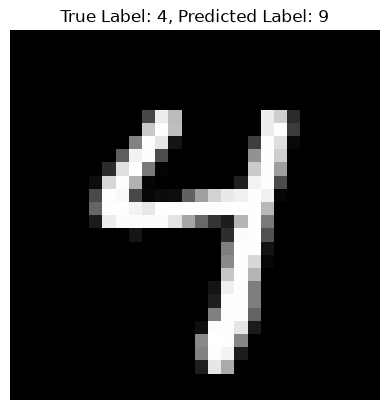

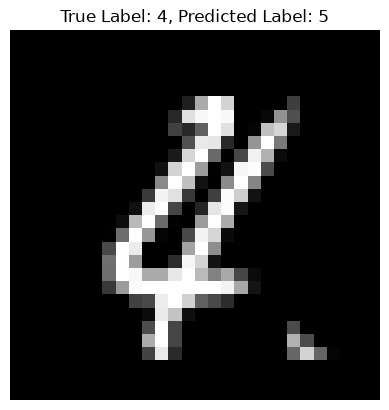

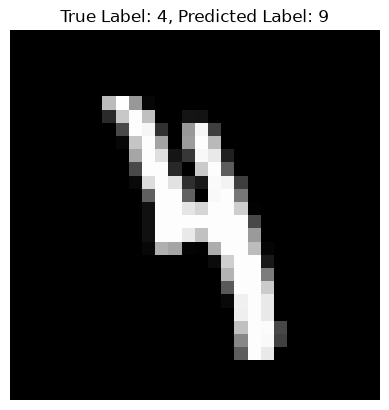

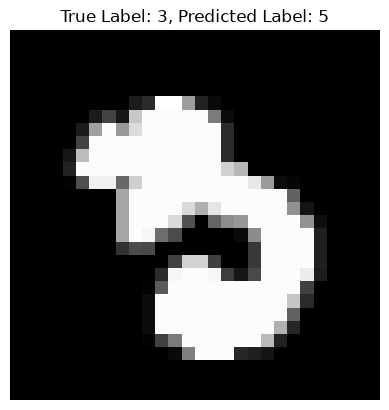

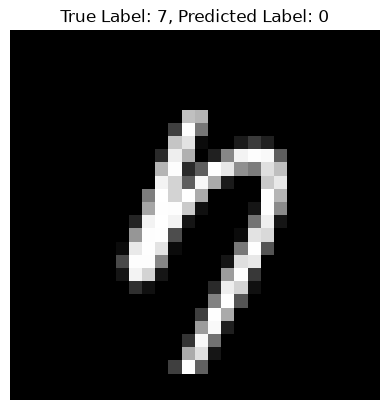

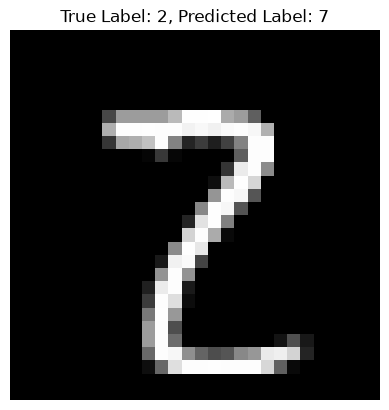

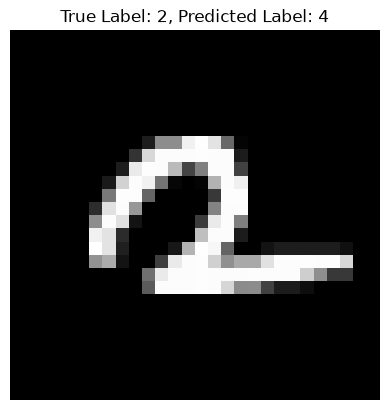

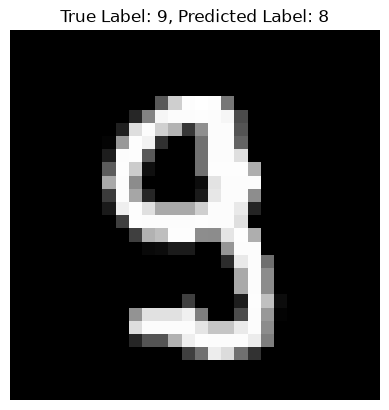

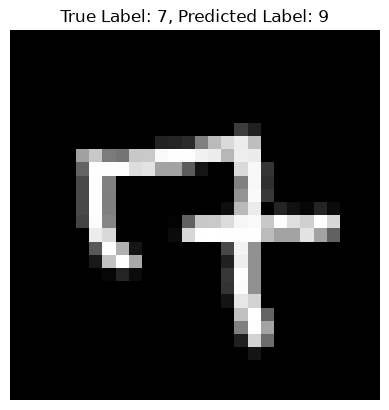

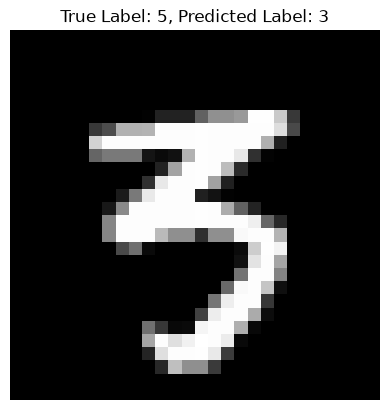

In [34]:
# Investigate misclassified samples
misclassified_indices = np.where(preds_np != labels_np)[0]
print(f"Number of misclassified samples: {len(misclassified_indices)}")

# Visualize some misclassified samples
num_samples_to_show = min(10, len(misclassified_indices))
for i in range(num_samples_to_show):
    idx = misclassified_indices[i]
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"True Label: {labels_np[idx]}, Predicted Label: {preds_np[idx]}"
    )
    plt.axis("off")
    plt.show()  